# E2 · Notebook 2 — Intervención preliminar: decoder de SAM 2.1 congelado vs ajustado

**NO EJECUTADO.** Solo E2. Compara el *mask decoder* **congelado** (época 0) con el **ajustado** (solo ese bloque; encoder de imagen y de prompts congelados), BCE+Dice sobre un subconjunto pequeño de train, evaluado en un subconjunto de val.

* **Referencia asistida por etiquetas, no desplegable**; DINOv3 no se usa. Preliminar: semilla 42, subconjuntos pequeños, sin test ni Bolivia.
* La hipótesis se guarda en tu Drive **antes** de cargar o entrenar el modelo (celda `prepare`).
* Los resultados reales aparecerán solo cuando tú ejecutes. Hasta revisar tus salidas, métricas e interpretación siguen **pendientes**.
* Requisito: haber ejecutado `E2_01_datos_baseline_teardown.ipynb` en tu cuenta. Runtime: **T4 GPU**.

## 1. Entorno (mismo commit que el notebook 1)

In [1]:
from pathlib import Path
import json, os, subprocess, sys
from google.colab import drive

drive.mount('/content/drive')
GITHUB_URL = 'https://github.com/roberto-chavez/auto-prompt-sam2.git'
BRANCH = '_E.V_'
PINNED_COMMIT = ''    # '' = usa el commit ya fijado en tu Drive; en la 1.ª ejecución fija la punta actual de la rama
UPDATE_CODE = False   # True SOLO para adoptar código nuevo de la rama (entonces rehaz E2 desde 'prepare')
PERSIST_ROOT = '/content/drive/MyDrive/auto-prompt-sam2'   # datos, pesos, cachés y checkpoints: SOLO aquí
REPO = Path('/content/auto-prompt-sam2')
PYTHON = Path('/content/auto-prompt-venv/bin/python')
Path(PERSIST_ROOT).mkdir(parents=True, exist_ok=True)

def sh(args, cwd=None):
    r = subprocess.run(args, cwd=cwd, text=True, capture_output=True)
    if r.returncode:
        raise RuntimeError(f'{args[:3]} falló:\n{r.stdout}\n{r.stderr}')
    return r.stdout.strip()

# --- Código desde GitHub, en una revisión fijada y reproducible --------------------------------------
PIN_FILE = Path(PERSIST_ROOT) / 'e2/code_commit.txt'
existed = REPO.exists()
if not existed:
    sh(['git', 'clone', '--branch', BRANCH, GITHUB_URL, str(REPO)])
elif UPDATE_CODE:
    sh(['git', 'fetch', 'origin', BRANCH], cwd=REPO)
want = PINNED_COMMIT.strip() or ('' if UPDATE_CODE or not PIN_FILE.exists() else PIN_FILE.read_text().strip())
if UPDATE_CODE and existed and not PINNED_COMMIT.strip():
    want = sh(['git', 'rev-parse', 'FETCH_HEAD'], cwd=REPO)
if want:
    sh(['git', 'checkout', '--detach', want], cwd=REPO)
COMMIT = sh(['git', 'rev-parse', 'HEAD'], cwd=REPO)
assert not sh(['git', 'status', '--porcelain'], cwd=REPO), 'El código clonado tiene cambios locales'
if PINNED_COMMIT.strip() or UPDATE_CODE or not PIN_FILE.exists():
    PIN_FILE.parent.mkdir(parents=True, exist_ok=True)
    PIN_FILE.write_text(COMMIT)
print('Código:', GITHUB_URL, '| rama', BRANCH, '| commit', COMMIT)
print('Commit fijado en Drive:', PIN_FILE.read_text().strip())

# --- Entorno ----------------------------------------------------------------------------------------
child_env = dict(os.environ, PYTHONPATH=str(REPO / 'src'),
    AUTO_PROMPT_PERSIST_ROOT=PERSIST_ROOT, PYTHONHASHSEED='42',
    CUBLAS_WORKSPACE_CONFIG=':4096:8', HF_HUB_DISABLE_TELEMETRY='1',
    AUTO_PROMPT_EXECUTION_CONTEXT='google_colab_user_notebook')
try:   # HF_TOKEN se lee de los secretos de Colab (activa "Acceso desde el notebook"); nunca se imprime ni se guarda
    from google.colab import userdata
    child_env['HF_TOKEN'] = userdata.get('HF_TOKEN')
    print('HF_TOKEN leído de los secretos de Colab (valor no mostrado).')
except Exception as error:
    print('HF_TOKEN no disponible (' + type(error).__name__ + '): SAM es público; solo DINOv3 lo necesita.')
LOG_DIR = Path(PERSIST_ROOT) / 'e2/notebook_logs'
LOG_DIR.mkdir(parents=True, exist_ok=True)

def command(args, log_name):
    """Ejecuta un proceso mostrando su salida en vivo y guardándola en Drive."""
    with (LOG_DIR / log_name).open('w', encoding='utf-8') as log:
        process = subprocess.Popen(args, cwd=REPO, env=child_env, text=True,
            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, bufsize=1)
        for line in process.stdout:
            print(line, end='')
            log.write(line)
            log.flush()
        result = process.wait()
    if result:
        raise RuntimeError(f'Proceso terminado con código {result}; revisa la salida y el log {log_name}')

if not PYTHON.is_file():
    command([sys.executable, str(REPO / 'scripts/bootstrap_colab.py'), '--venv', str(PYTHON.parent.parent)], 'bootstrap.log')
command([str(PYTHON), '-m', 'pip', 'install', '--no-deps', '-r', str(REPO / 'requirements-stage2.txt')], 'stage2_pins.log')
command([str(PYTHON), '-m', 'pip', 'check'], 'pip_check.log')
print('Entorno listo.')

Mounted at /content/drive
Código: https://github.com/roberto-chavez/auto-prompt-sam2.git | rama _E.V_ | commit f399047464b89a3ed18972f8dc7f1b1364d83a44
Commit fijado en Drive: f399047464b89a3ed18972f8dc7f1b1364d83a44
HF_TOKEN no disponible (TimeoutException): SAM es público; solo DINOv3 lo necesita.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 52.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 81.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 13.2 MB/s eta 0:00:00
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 141.4 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 561.5/561.5 kB 45.3 MB/s  0:00:00
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 536.2/536.2 kB 37.2 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━

In [2]:
# Comprueba que Colab te dio una GPU (Entorno de ejecución > Cambiar tipo > T4 GPU).
command(['nvidia-smi'], 'nvidia_smi.log')
command([str(PYTHON), '-c', 'import torch; assert torch.cuda.is_available(), "NO HAY GPU: cambia el tipo de entorno a GPU"; print("GPU:", torch.cuda.get_device_name(0), "| torch", torch.__version__)'], 'gpu_check.log')

Fri Oct 30 01:30:59 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   42C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Prerrequisitos en tu Drive

In [3]:
# E2 lee lo que dejó TU ejecución del notebook E2_01 en TU Drive. Nada depende de archivos de otra persona.
root = Path(PERSIST_ROOT)
required = {
    'raw/acquisition (descarga Sen1Floods11)': root / 'raw/acquisition',
    'stage2/validation (datos preparados)': root / 'stage2/validation',
    'regimes/official/manifests': root / 'regimes/official/manifests',
    'regimes/official/preprocessing': root / 'regimes/official/preprocessing',
}
for name, path in required.items():
    print(('OK       ' if path.exists() else 'FALTA    ') + name)
assert all(p.exists() for p in required.values()), 'Faltan datos: ejecuta primero E2_01_datos_baseline_teardown.ipynb completo (celda de la etapa 2).'
for label, folder in (('línea base (etapa 3)', root / 'stage3/evidence'), ('teardown (etapa 4)', root / 'stage4/evidence')):
    done = sorted(p.name for p in folder.glob('*/validation.json')) if folder.exists() else []
    print(('OK       ' if done else 'AVISO    ') + label + ': ' + ('run en tu Drive' if done else 'aún no ejecutada en tu Drive (E2 puede correr, pero la evidencia de Fase A estará incompleta)'))

OK       raw/acquisition (descarga Sen1Floods11)
OK       stage2/validation (datos preparados)
OK       regimes/official/manifests
OK       regimes/official/preprocessing
OK       línea base (etapa 3): run en tu Drive
OK       teardown (etapa 4): run en tu Drive


## 3. Hipótesis y configuración (antes de entrenar)
Tal como están en `configs/e2_intervention.yaml` del commit fijado. No se cambian tras ver resultados.

In [4]:
print(json.dumps(json.loads((REPO / 'configs/e2_intervention.yaml').read_text()), indent=2, ensure_ascii=False))

{
  "schema_version": 1,
  "stage": "e2_preliminary_decoder_intervention",
  "scope_note": "Preliminary E2 experiment. Label-simulated points (stage-3 reference-assisted policy) isolate the decoder effect; this is NOT the automatic DINOv3 -> SAM flow. Conclusions are limited to the subsets below.",
  "seed": 42,
  "regime": "official",
  "model_integrity": {
    "source": "audited stage-3 and stage-4 Colab evidence (docs/project/evidence/stage3, stage4)",
    "expected_checkpoint_sha256": "7402e0d864fa82708a20fbd15bc84245c2f26dff0eb43a4b5b93452deb34be69",
    "expected_state_sha256": "72a85430eb2c93ee9fe3fed9a2ed1e097a8756f15c0becb212586afe7112384d"
  },
  "subset": {
    "train_chips_per_event": 3,
    "val_chips_per_event": 4,
    "order": "events_alphabetical_then_lexicographic_id_label_free",
    "reserved_sets": "forbidden"
  },
  "prompts": {
    "connectivity": 8,
    "positive_per_component": 1,
    "negative_per_component": 1,
    "minimum_distance_px": 8.0,
    "sampling": "s

## 4. Ejecutar E2 (`prepare`)
En orden: pruebas, verificación del hash de SAM, **guardado de la hipótesis**, paridad con el predictor de la etapa 3, época 0 (decoder congelado), entrenamiento solo del decoder con auditoría de gradientes, evaluación de la mejor época y evidencia. Imprime el tiempo por época (no estimado de antemano).

Si Colab se corta durante el entrenamiento: reconecta, ejecuta las celdas 1–2 y cambia `MODE` a `'resume'` (nunca dos escritores).

In [5]:
MODE = 'prepare'   # 'resume' SOLO para continuar un run interrumpido
assert MODE in ('prepare', 'resume')
command([str(PYTHON), str(REPO / 'scripts/run_e2.py'), MODE, '--root', PERSIST_ROOT], MODE + '.log')

HYPOTHESIS (recorded before training):
{
  "recorded_before_training": true,
  "statement": "With identical simulated points, identical validation chips and the same evaluator, fine-tuning ONLY the SAM 2.1 mask decoder (BCE + Dice) on the small training subset will raise the pooled water IoU on the validation subset above the frozen decoder (epoch 0).",
  "mechanism": "The stage-3 reference over-segments on full validation (official: precision 0.161, recall 0.894, IoU 0.158). The decoder can learn to suppress Sentinel-2 false positives, so precision should rise more than recall falls. The magnitude is not predicted.",
  "risks": "Only a small subset is used (overfitting is possible); the IoU-prediction head receives no gradient from BCE + Dice (selection by predicted IoU may become mismatched); chips without water produce no components and no update.",
  "refuted_if": "The best-epoch pooled validation water IoU is less than or equal to the frozen-decoder pooled validation water IoU on 

## 5. Ver resultados medidos
Todo sale de `report.json`; no hay números escritos a mano.

run_id: 20261030T013250Z_2a795a89d5_f9fbd8b0 | estado: executed_pending_review
{
  "hipotesis_previa": "With identical simulated points, identical validation chips and the same evaluator, fine-tuning ONLY the SAM 2.1 mask decoder (BCE + Dice) on the small training subset will raise the pooled water IoU on the validation subset above the frozen decoder (epoch 0).",
  "brazos": {
    "frozen_epoch0": {
      "arm": "frozen_decoder",
      "chips": 40,
      "water_iou_pooled": 0.17037849358838072,
      "event_mean_water_iou": 0.18776266906942046,
      "precision": 0.17147522573942403,
      "recall": 0.9638190533871113,
      "dice": 0.2911511011553198,
      "miou": 0.32829103317543606,
      "per_chip_median": 0.0676911329579078,
      "per_chip_iqr": 0.17907758107500543,
      "chips_in_individual_iou": 33,
      "fp_area_m2_total": 401135104.6685248
    },
    "tuned_best_epoch": {
      "arm": "finetuned_decoder_best_epoch_1",
      "chips": 40,
      "water_iou_pooled": 0.3080519

epoch,train_bce,train_dice,train_loss,train_chips_with_gradient,train_chips_without_gradient,optimizer_steps,val_water_iou_pooled,val_event_mean_water_iou,seconds
1,1.1086803576103053,0.7543049317139846,1.8629852848557324,26,4,7,0.3080519029370676,0.245350354741417,161.02723336219788
2,0.2933996932921358,0.6840517566754267,0.977451435648478,26,4,7,0.112774314093841,0.14375343065433785,161.06664896011353
3,0.2517523730359524,0.6832939776090475,0.9350463576041735,26,4,7,0.0956895402617404,0.13411751918924567,161.04032349586487
4,0.24707183886382084,0.6293205550083747,0.876392397743005,26,4,7,0.14992778300691617,0.1763771214397873,161.1534285545349


per_chip_val.csv


id,event,components,iou_frozen,iou_tuned,delta,precision_frozen,precision_tuned,recall_frozen,recall_tuned,dice_frozen,dice_tuned,fp_pixels_frozen,fp_pixels_tuned,exclusion
Ghana_1033830,Ghana,52,0.4612256592241111,0.3415700453700002,-0.11965561385411089,0.47324311221595305,0.6829620103576518,0.947815847372716,0.405935275950047,0.6312860115925079,0.5092094096000725,102135,18243,
Ghana_124834,Ghana,0,,,,,,,,,,0,0,no_valid_water
Ghana_132163,Ghana,0,,,,,,,,,,0,0,no_valid_water
Ghana_142312,Ghana,0,,,,,,,,,,0,0,no_valid_water
India_1018317,India,80,0.7552107267955435,0.5500050640888579,-0.2052056627066856,0.766184385700447,0.78348829753126,0.9813880963439718,0.6485833720390153,0.8605356784416627,0.7096816350237776,45136,27012,
India_1050276,India,593,0.19206362271635133,0.2272561449879888,0.035192522271637466,0.19206663400293975,0.25535996039971537,0.9999183756759514,0.6737271706968677,0.3222372011968566,0.3703483513463491,206124,96276,
India_1068117,India,480,0.2088022604281404,0.2714189565347448,0.06261669610660439,0.2088022604281404,0.310935328497725,1.0,0.6810884070058382,0.34546967235846443,0.42695439632974763,181731,72389,
India_118868,India,120,0.06662341273519325,0.18994933588936053,0.12332592315416728,0.06662341273519325,0.21231136551470814,1.0,0.6432943795214245,0.1249239646153044,0.3192561736208603,151053,25733,
Mekong_1149855,Mekong,140,0.07844760908139588,0.2238514607688724,0.14540385168747655,0.07845403418087836,0.26618306515431284,0.9989571263035921,0.5846465816917729,0.14548246650241317,0.3658147543955048,202530,27819,
Mekong_1413877,Mekong,69,0.009995344525042079,0.15642221280203475,0.14642686827699267,0.009995344525042079,0.1657979870596693,1.0,0.7344745222929936,0.019792852668528812,0.27052785923753664,248805,9283,


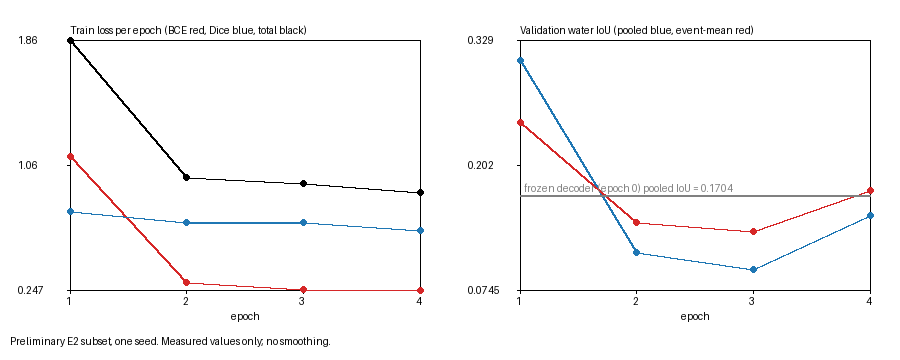

Ghana_1033830.png


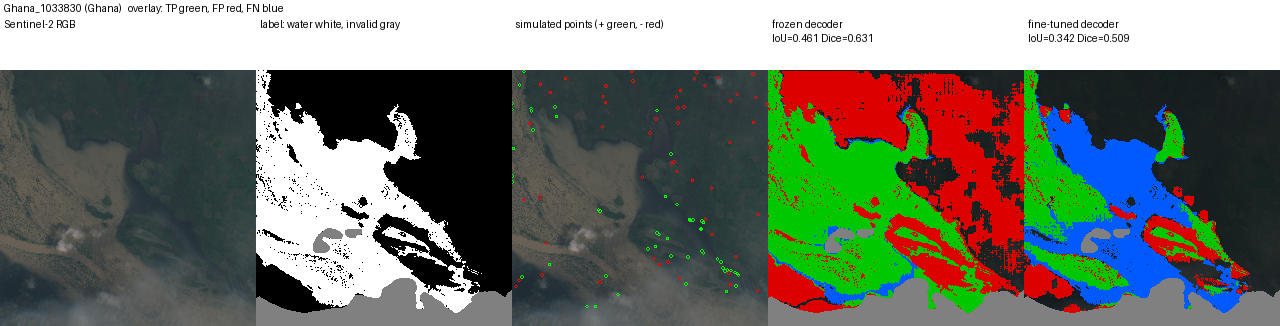

India_1018317.png


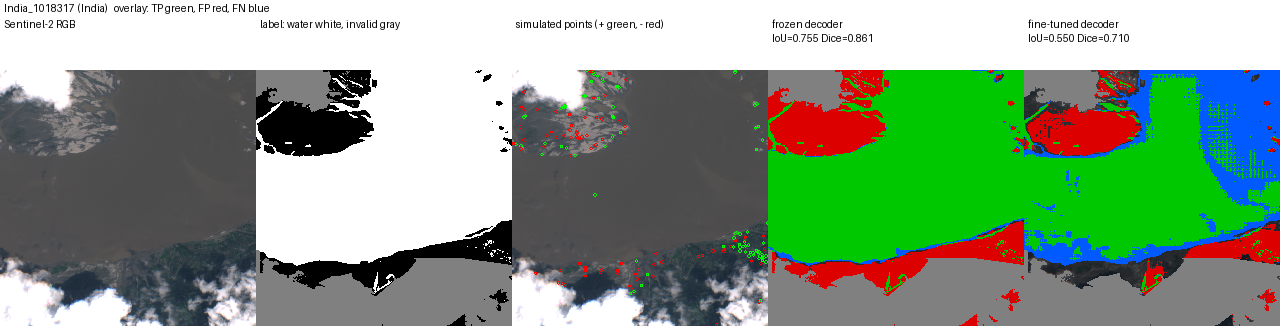

Mekong_1149855.png


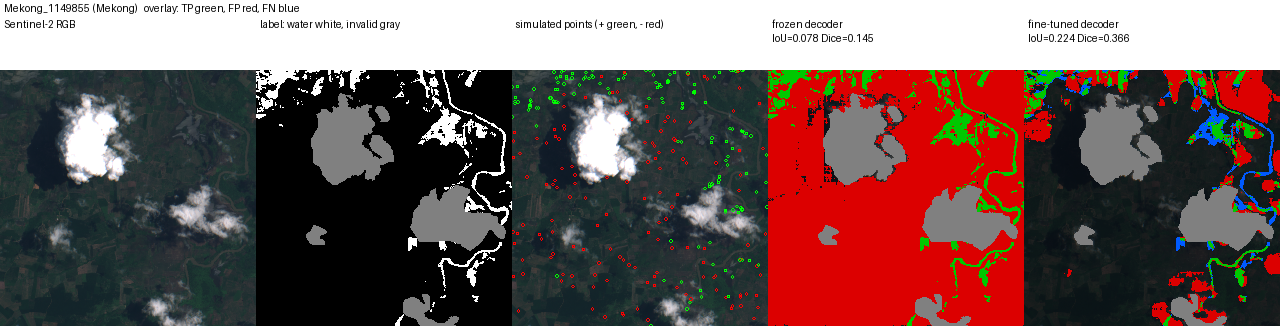

Nigeria_1095404.png


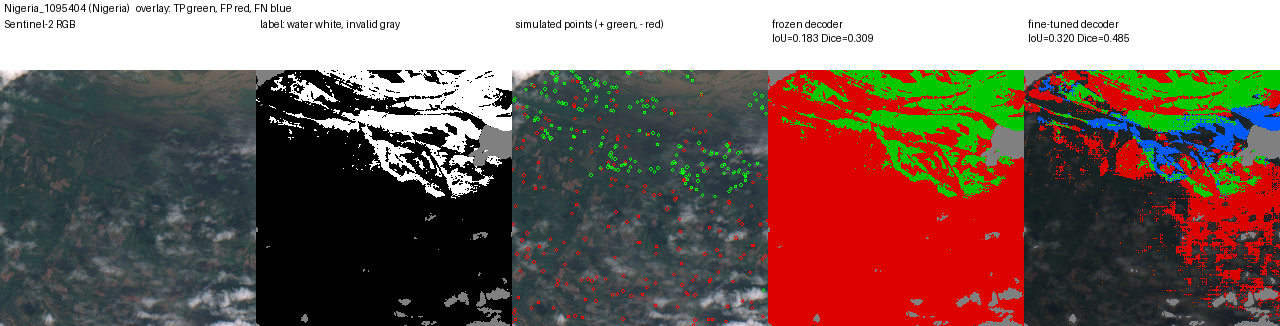

Pakistan_1027214.png


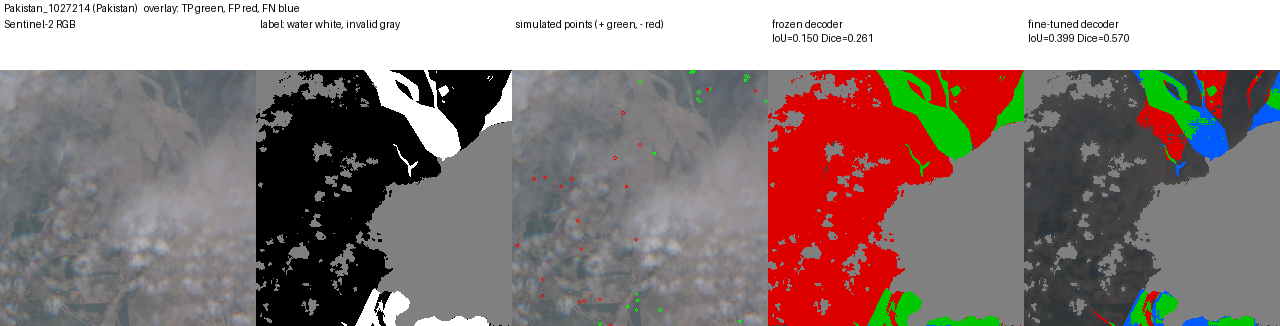

Paraguay_1019808.png


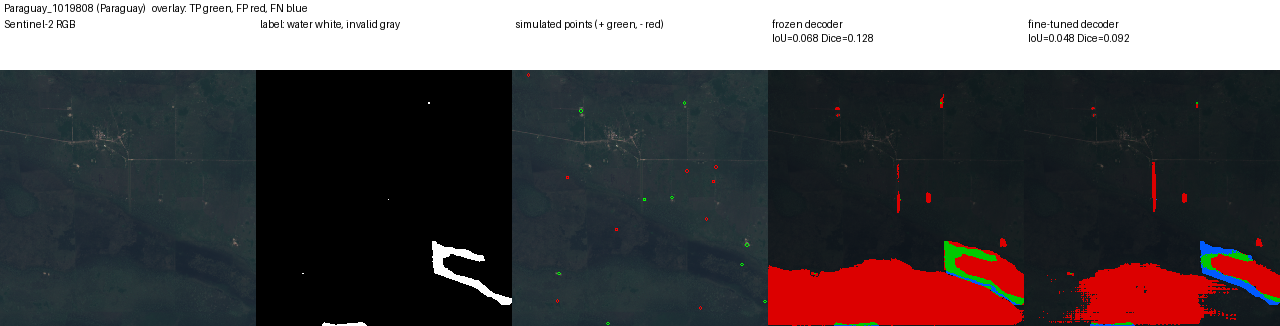

Somalia_12849.png


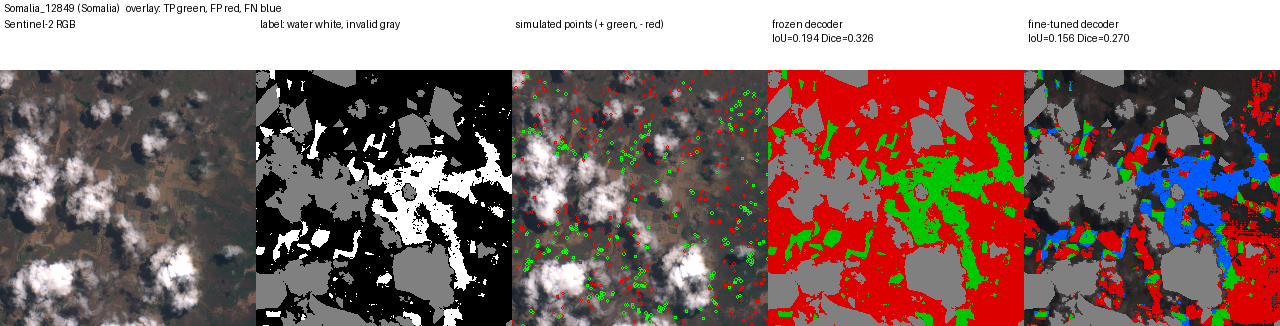

Spain_1199913.png


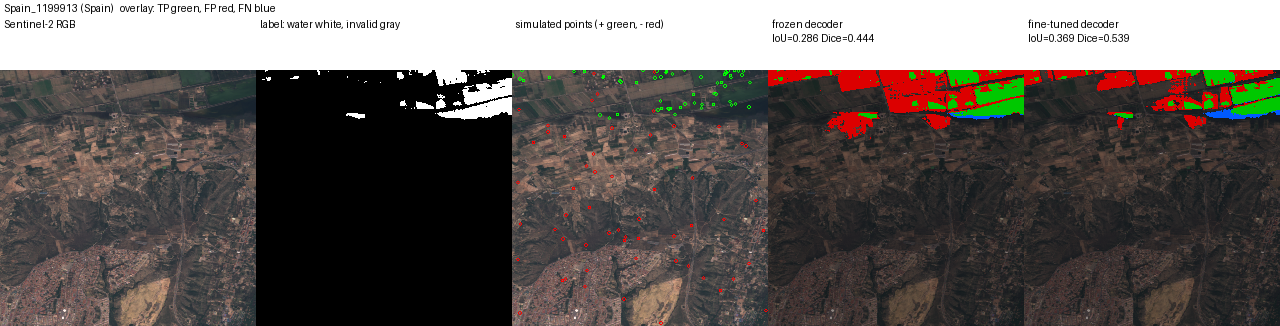

Sri-Lanka_101973.png


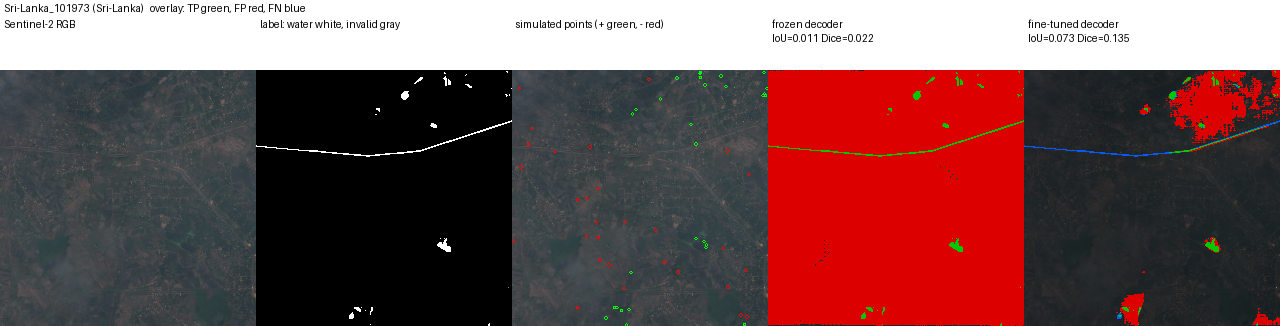

USA_1039203.png


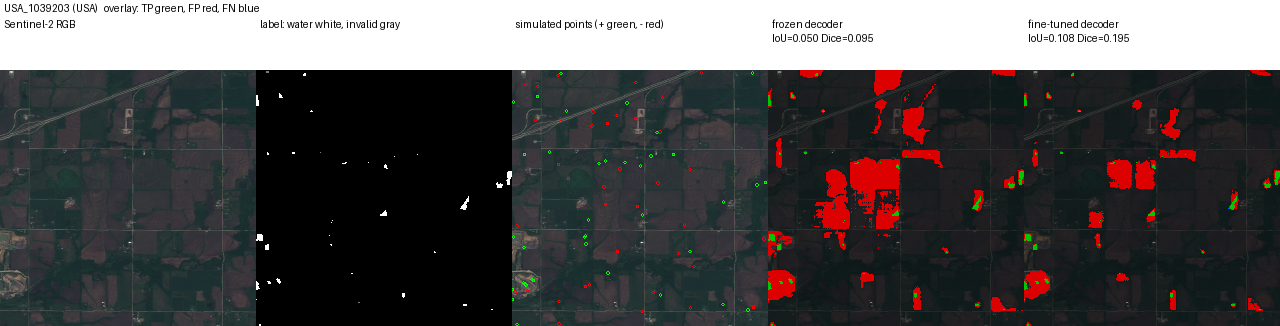

Limitaciones declaradas:
 - Preliminary: official regime, small label-free subsets of train/val, one seed. No claim about unseen events, Bolivia or Paraguay-out.
 - Prompts are label-simulated (reference-assisted, not deployable). The automatic DINOv3 -> SAM flow is NOT implemented here.
 - Chips without water have no components: empty prediction and FP=0 by construction in BOTH arms (label-assisted advantage); they produce no gradient.
 - Validation is used both to pick the best epoch and to report the result: the best-epoch number is optimistic. The last-epoch number is also reported.
 - The IoU-prediction head receives no gradient from BCE+Dice, so selection by predicted IoU may drift away from true mask quality after tuning.
 - No significance test, no repeated seeds. Per-chip deltas are descriptive.


[None, None, None, None, None, None]

In [6]:
from IPython.display import display, Image, HTML
import csv, html
EVIDENCE = Path(PERSIST_ROOT) / 'e2/evidence'
RUNS = sorted(p for p in EVIDENCE.iterdir() if p.is_dir() and (p / 'report.json').is_file())
assert RUNS, 'No hay un prepare completo. Conserva e2/notebook_logs/prepare.log.'
RUN_DIR = RUNS[-1]
REPORT = json.loads((RUN_DIR / 'report.json').read_text())
print('run_id:', REPORT['run_id'], '| estado:', REPORT['status'])
print(json.dumps({'hipotesis_previa': REPORT['hypothesis']['statement'], 'brazos': REPORT['arms'],
                  'mejor_epoca': REPORT['best_epoch'], 'verificacion_hipotesis': REPORT['hypothesis_check'],
                  'congelamiento': {k: REPORT['freezing'][k] for k in ('frozen_blocks_unchanged', 'decoder_changed')},
                  'paridad_con_etapa3': REPORT['parity_with_stage3_predictor'],
                  'subconjuntos': {k: REPORT['subsets'][k] for k in ('val_stats', 'train_stats')}},
                 indent=2, ensure_ascii=False))
for name in ('history.csv', 'per_chip_val.csv'):
    rows = list(csv.reader((RUN_DIR / name).open(encoding='utf-8', newline='')))
    print(name)
    display(HTML('<table>' + ''.join('<tr>' + ''.join('<td>' + html.escape(v) + '</td>' for v in row) + '</tr>' for row in rows) + '</table>'))
display(Image(filename=str(RUN_DIR / 'curves.png')))
for figure in sorted((RUN_DIR / 'examples').glob('*.png')):
    print(figure.name)
    display(Image(filename=str(figure)))
print('Limitaciones declaradas:'); [print(' -', item) for item in REPORT['limitations']]

## 6. Borrador del cuaderno de decisiones
Copia solo las cifras medidas a un `.md`. La **interpretación** debe escribirla el equipo.

In [7]:
EVID = Path(PERSIST_ROOT) / 'e2/evidence'
RUN_DIR = sorted(p for p in EVID.iterdir() if p.is_dir() and (p / 'report.json').is_file())[-1]
# Borrador (solo cifras medidas) para pegar en docs/project/cuaderno_decisiones.md; la interpretación queda PENDIENTE.
command([str(PYTHON), str(REPO / 'scripts/e2_decision_log_draft.py'), str(RUN_DIR)], 'decision_log_draft.log')
print('\nArchivo:', RUN_DIR / 'e2_resultados_para_cuaderno_decisiones.md')

### Resultados medidos (E2) — run `20261030T013250Z_2a795a89d5_f9fbd8b0`

_Generado automáticamente desde `report.json`. Solo cifras medidas; la interpretación es del equipo._

| Brazo | IoU agua agrupado | IoU medio por evento | Precisión | Recall | Dice | Mediana IoU por chip |
| --- | --- | --- | --- | --- | --- | --- |
| frozen_decoder | 0.1704 | 0.1878 | 0.1715 | 0.9638 | 0.2912 | 0.0677 |
| finetuned_decoder_best_epoch_1 | 0.3081 | 0.2454 | 0.3988 | 0.5752 | 0.4710 | 0.1795 |

Mejor época (por IoU agrupado en val): **1**; IoU agrupado de la última época: 0.1499.

Criterio prefijado de refutación: The best-epoch pooled validation water IoU is less than or equal to the frozen-decoder pooled validation water IoU on the same chips.
Resultado mecánico del criterio: **not_refuted_on_this_subset** (congelado 0.1704 vs ajustado 0.3081). Interpretación: **PENDIENTE**.

| Época | BCE | Dice | Pérdida | IoU val agrupado | s |
| --- | --- | --- | --- | --- | --- |
| 1 | 1.1087 | 0.7543 | 1.8

## 7. Recuperar en un runtime nuevo (`recover`)
Descarga primero la evidencia (sección 8). Luego *Entorno de ejecución → Desconectar y eliminar*, reconecta con T4, ejecuta **solo** las celdas 1–2 (entorno y prerrequisitos) y la celda siguiente. **No repitas `prepare`.** Recarga SAM desde tu Drive offline, verifica el hash, recarga el mejor decoder y reevalúa ambos brazos; deben coincidir (IoU agrupado a 1e-6 y confusiones por chip idénticas). Si falla, no cambies tolerancias.

In [8]:
command([str(PYTHON), str(REPO / 'scripts/run_e2.py'), 'recover', '--root', PERSIST_ROOT], 'recover.log')

E2 recover 20261030T013250Z_2a795a89d5_f9fbd8b0
val chips ready {'chips': 40, 'per_event': {'Ghana': 4, 'India': 4, 'Mekong': 4, 'Nigeria': 4, 'Pakistan': 4, 'Paraguay': 4, 'Somalia': 4, 'Spain': 4, 'Sri-Lanka': 4, 'USA': 4}, 'components_total': 3893, 'components_min': 0, 'components_max': 593, 'chips_without_components': 7}
{
  "frozen_arm_check": {
    "pooled_iou_now": 0.17037849358838072,
    "pooled_iou_saved": 0.17037849358838072,
    "abs_diff": 0.0,
    "tolerance": 1e-06,
    "per_chip_confusions_identical": true,
    "mask_disagreement_pixels": 0,
    "passed": true
  },
  "tuned_arm_check": {
    "pooled_iou_now": 0.3080519029370676,
    "pooled_iou_saved": 0.3080519029370676,
    "abs_diff": 0.0,
    "tolerance": 1e-06,
    "per_chip_confusions_identical": true,
    "mask_disagreement_pixels": 0,
    "passed": true
  }
}


## 8. Descargar la evidencia
El ZIP incluye informe, tablas, curvas, ejemplos, predicciones, puntos, el borrador y el commit de código. **No** incluye checkpoints, pesos, tokens ni imágenes de entrenamiento.

In [9]:
from google.colab import files
import hashlib
# Regenera el ZIP incluyendo el borrador del cuaderno de decisiones y el commit de código usado.
import zipfile
EVID = Path(PERSIST_ROOT) / 'e2/evidence'
RUN_DIR = sorted(p for p in EVID.iterdir() if p.is_dir() and (p / 'report.json').is_file())[-1]
(RUN_DIR / 'code_commit.txt').write_text(COMMIT)
target = RUN_DIR.with_name(RUN_DIR.name + '-final.zip')
with zipfile.ZipFile(target, 'w', zipfile.ZIP_DEFLATED) as archive:
    for p in sorted(RUN_DIR.rglob('*')):
        if p.is_file():
            archive.write(p, p.relative_to(RUN_DIR.parent).as_posix())
print(target, hashlib.sha256(target.read_bytes()).hexdigest())
files.download(str(target))

/content/drive/MyDrive/auto-prompt-sam2/e2/evidence/20261030T013250Z_2a795a89d5_f9fbd8b0-final.zip 4e67a5fb03d69460d2d1cf236ab61c42ba67e24cc0d4800c665af78a8be3eac4


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Qué devolver y qué NO afirmar
Devuelve: **este notebook ejecutado** (y el E2_01 ejecutado), el ZIP final de evidencia y, si hubo errores, `e2/notebook_logs/*.log`. E2 **no queda acreditada** por crear o correr estos cuadernos: falta revisar resultados, interpretarlos (incluyendo fallos y límites) y completar el cuaderno de decisiones. IA: Claude preparó código, pruebas y documentación; la comprensión y la defensa oral son tuyas.